# Analysis Human-Team


Maximilian and Florian doing phase 1.


question 1: Florian
Question 2: Max
Question 3: Max
Question 4: Florian

### Load and Import

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch
from tqdm.auto import tqdm

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------
from pair_b.q2_helpers import (relation_features, image_stats, ego_share, seq_share,
                               gallery, model_view)

print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()

# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")

c:\Users\maxha\Documents\JKU\WS26\AI_visualisation_UE\ai_and_visualisation_OpenSI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.11.0+cu128 | CUDA build 12.8
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP


•    Q2 (overconfidence and training coverage): When is the model confidently wrong and what do those images share: scene type, misleading clues, or image quality (dashcam, blur, night), …. ? Can we infer from this behavior which countries were in StreetCLIP’s Street View training and does that match the published, contradictory list (e.g., India and China)? (Is there a hard cut in countries the model is better at?)


In [2]:
THRESHOLD = 0.8
attrs = mapper.table

# only images whose true country is a candidate, the others can never be correct
df = preds[preds["representable"]].copy()
df["correct"] = df["correct"].astype(bool)
df["confidence"] = df["prob_1"]
df["in_list"] = df["country_id"].map(attrs["in_paper_training_list"]).fillna(0).astype(int) == 1

high = df["confidence"] > THRESHOLD
df["group"] = np.select(
    [high & ~df["correct"], high & df["correct"], ~high & df["correct"]],
    ["high-conf ERROR", "high-conf correct", "low-conf correct"],
    default="low-conf error")

# does the exact threshold matter?
for t in [0.6, 0.7, 0.8, 0.9]:
    conf = df[df["confidence"] > t]
    print(f"> {t}: {len(conf):7,} images, error rate {1 - conf['correct'].mean():.3f}")

df["group"].value_counts()


> 0.6:  85,404 images, error rate 0.192
> 0.7:  67,949 images, error rate 0.143
> 0.8:  50,929 images, error rate 0.103
> 0.9:  32,371 images, error rate 0.061


group
low-conf error       97268
low-conf correct     60117
high-conf correct    45672
high-conf ERROR       5257
Name: count, dtype: int64

## F1: Does confidence mean the same for listed and unlisted countries?

If StreetCLIP saw a country during fine-tuning, its confidence there should be trustworthy. We compare reliability curves for listed and unlisted countries; the small numbers are images per bin, because bins with few images are mostly noise.

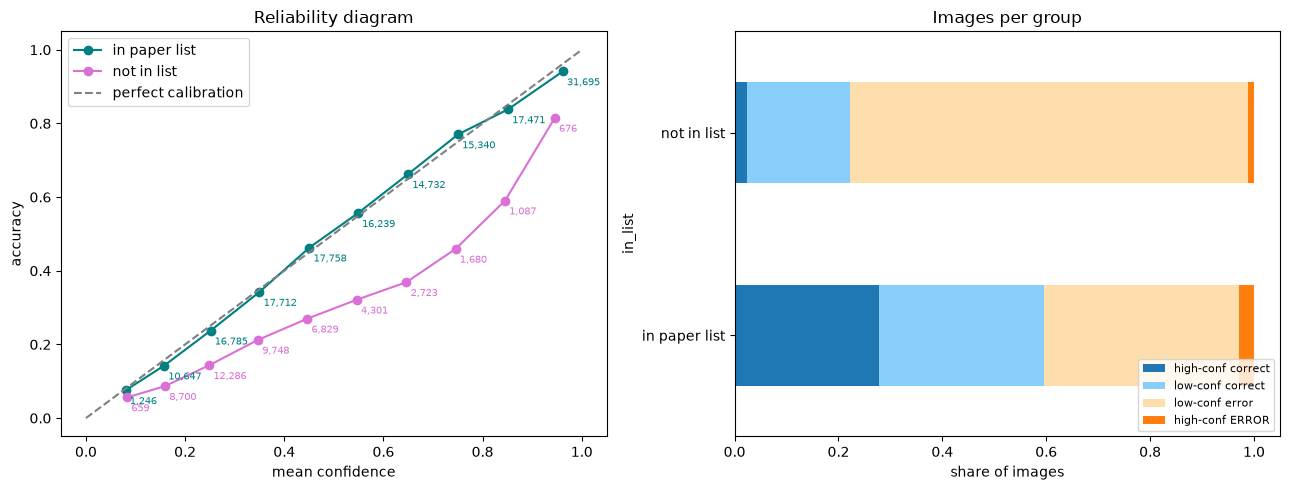

,all countries,without US
in_list,,
not in list,0.012,0.012
in paper list,0.029,0.018


In [3]:
def reliability(ax, data, by, labels):
    for val, (label, color) in labels.items():
        part = data[data[by] == val]
        b = part.groupby(pd.cut(part["confidence"], np.linspace(0, 1, 11)), observed=True).agg(
            conf=("confidence", "mean"), acc=("correct", "mean"), n=("correct", "size"))
        ax.plot(b["conf"], b["acc"], marker="o", color=color, label=label)
        for _, r in b.iterrows():
            ax.annotate(f"{int(r['n']):,}", (r["conf"], r["acc"]), fontsize=7, color=color,
                        xytext=(3, -10), textcoords="offset points")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.set_xlabel("mean confidence")
    ax.set_ylabel("accuracy")
    ax.legend()

LIST_LABELS = {True: ("in paper list", "teal"), False: ("not in list", "orchid")}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
reliability(axes[0], df, "in_list", LIST_LABELS)
axes[0].set_title("Reliability diagram")

order = ["high-conf correct", "low-conf correct", "low-conf error", "high-conf ERROR"]
shares = pd.crosstab(df["group"], df["in_list"].map({True: "in paper list", False: "not in list"}),
                     normalize="columns").reindex(order).fillna(0)
shares.T.plot(kind="barh", stacked=True, ax=axes[1],
              color=["tab:blue", "lightskyblue", "navajowhite", "tab:orange"])
axes[1].set_xlabel("share of images")
axes[1].set_title("Images per group")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

def conf_error_rate(data):
    return data.groupby("in_list")["group"].apply(lambda g: (g == "high-conf ERROR").mean())

check = pd.DataFrame({"all countries": conf_error_rate(df),
                      "without US": conf_error_rate(df[df["country_id"] != "US"])})
check.index = check.index.map({True: "in paper list", False: "not in list"})
display(check.round(3))

**F1 notes:** For listed countries the curve sits almost on the diagonal, so a 90% guess is right about 90% of the time. Unlisted countries are clearly below it: at around 0.55 confidence they're only right about 32% of the time, at 0.75 about 46%. So the model is less sure on unlisted countries, but still not unsure enough. Most of their images end up as low-confidence errors (about 77%), and only around 2% are confident and correct, compared to about 28% for listed countries. One caveat: unlisted countries are also harder overall, and harder countries tend to be worse calibrated anyway, so not all of the gap has to come from missing training data. Moving the threshold between 0.6 and 0.9 changes the error rate of the confident group (19% to 6%) but not the picture, so we stay with 0.8 (10% errors).

Surprisingly, confident mistakes are more common in listed countries (2.9% vs 1.2%). Without the US this becomes 1.8% vs 1.2%, so most of the gap comes from US images. What are these confident mistakes?

## F2: What do the confident mistakes have in common?

We take all high-confidence errors and a reference of high-confidence correct images **with the same country mix** (otherwise the US-heavy errors would differ from the reference just because of the country). A feature only matters if it's clearly more common among the errors, and every drive is counted once, since some drives contribute many near-identical images.

In [4]:
errors = df[df["group"] == "high-conf ERROR"]
correct = df[df["group"] == "high-conf correct"]

parts = []
for c, n in errors["country_id"].value_counts().items():
    pool = correct[correct["country_id"] == c]
    if len(pool) > 0:
        parts.append(pool.sample(min(n, len(pool)), random_state=0))
reference = pd.concat(parts)

work = pd.concat([errors, reference]).reset_index(drop=True)
work["is_error"] = work["group"] == "high-conf ERROR"
# relation between true country and the guess (errors) or the 2nd guess (correct ones)
work = relation_features(work, attrs)

print(f"{len(errors):,} errors, {len(reference):,} reference images "
      f"({len(errors) - len(reference):,} short because some countries have few correct ones)")

5,257 errors, 4,828 reference images (429 short because some countries have few correct ones)


In [5]:
def quality(img):
    g = np.asarray(img, dtype=np.float32)
    if g.ndim == 3:
        g = g.mean(axis=2)
    lap = g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:] - 4 * g[1:-1, 1:-1]
    return {"brightness": g.mean(), "contrast": g.std(), "sharpness": lap.var()}

segmenter = Segmenter(cfg)
ego_ids = [int(i) for i, name in segmenter.model.config.id2label.items() if "ego" in name.lower()]

rows = []
for image_id in tqdm(work["id"], desc="image stats + segmentation"):
    img = model_view(dataset, image_id, cfg.crop_mode)
    rows.append({**image_stats(img), **quality(img),
                 "ego_share": ego_share(segmenter, img, image_id, ego_ids)})
free_gpu_memory()

work = pd.concat([work, pd.DataFrame(rows)], axis=1)
work["rotated"] = work["top_minus_bottom"] < -40   # sky clearly at the bottom
# rotated images get segmented as ego vehicle almost completely, so we leave them out
work["hood_visible"] = (work["ego_share"] > 0.03) & ~work["rotated"]

need = [c for c in ["sequence", "region", "land_cover_name"] if c not in work.columns]
if need:
    work = work.merge(preds[["id"] + need], on="id", how="left")
work.to_csv("results/pair_b/q2_features.csv", index=False)
print(f"{len(work):,} rows, {work['sequence'].nunique():,} drives")

W1105 23:24:46.421000 41268 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 758/758 [00:00<00:00, 821.16it/s] 
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-mapillary-vistas-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                          

10,085 rows, 7,611 drives


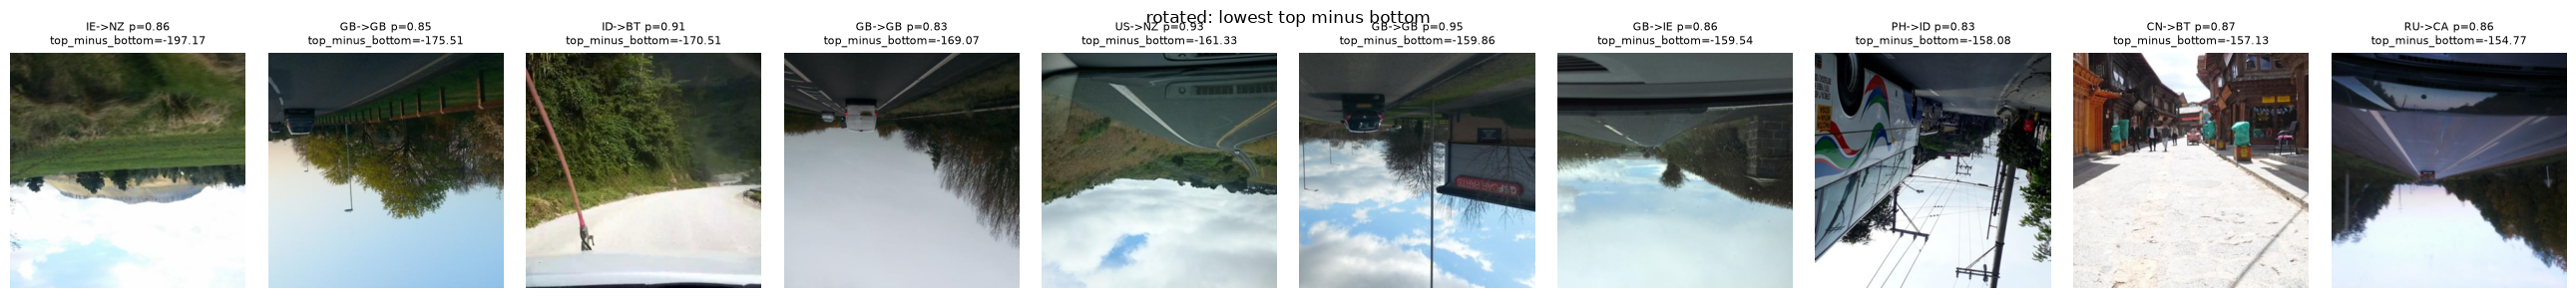

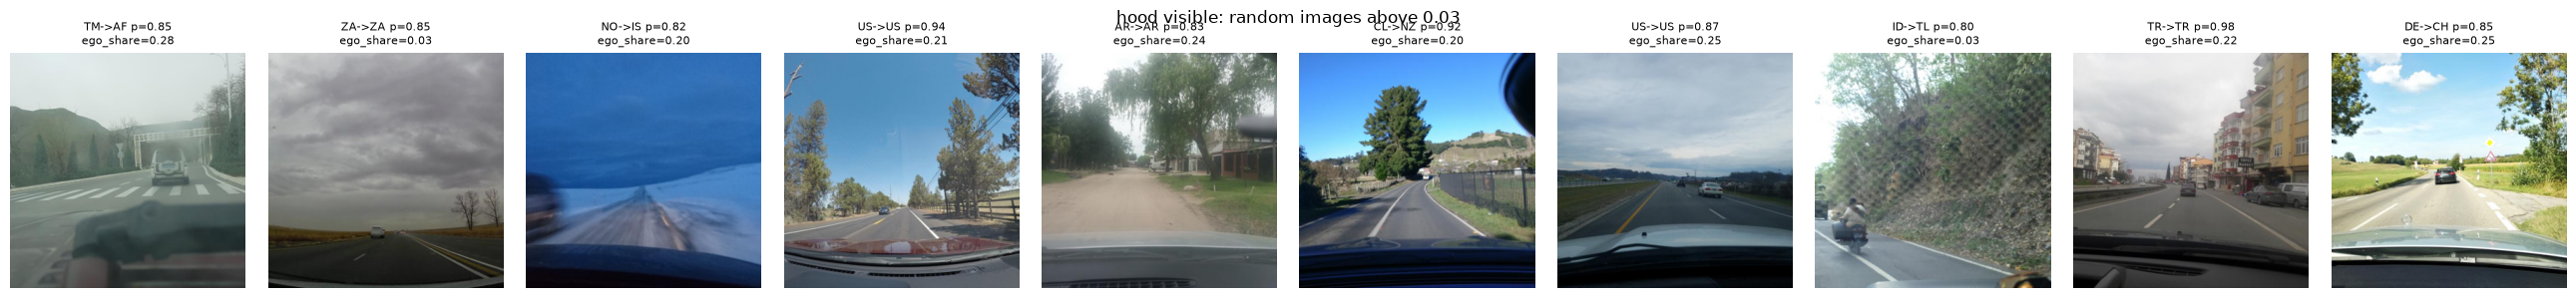

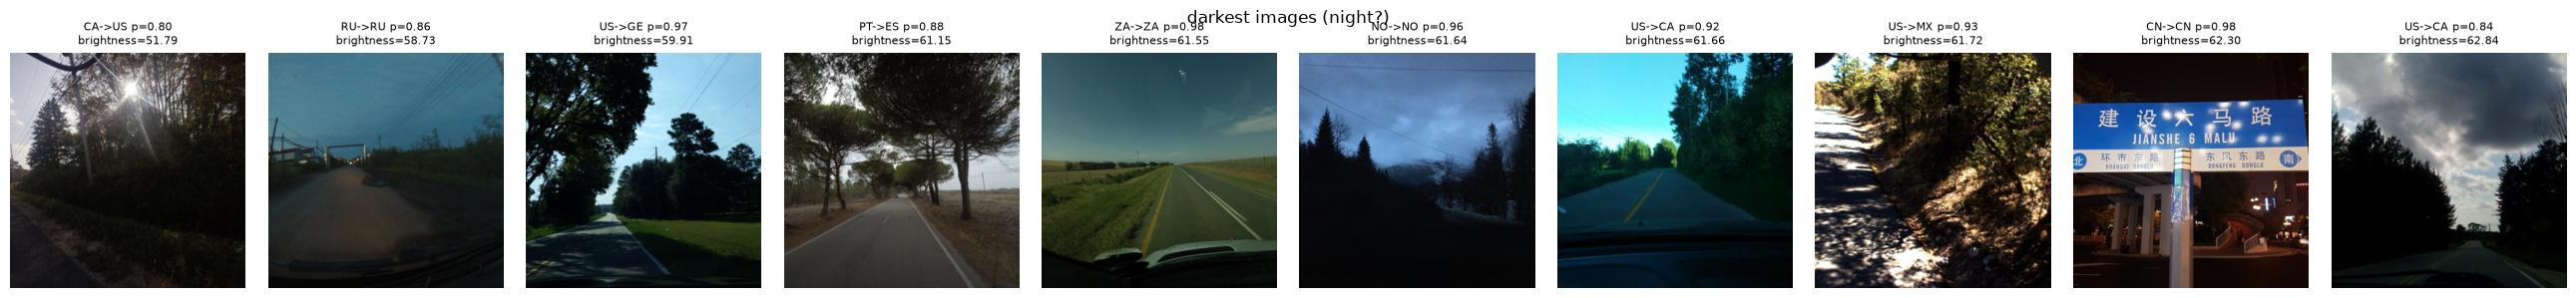

In [6]:
# sanity check of the flags before using them
gallery(dataset, work.nsmallest(10, "top_minus_bottom"), cfg.crop_mode,
        "rotated: lowest top minus bottom", label_col="top_minus_bottom")
gallery(dataset, work[work["hood_visible"]].sample(10, random_state=0), cfg.crop_mode,
        "hood visible: random images above 0.03", label_col="ego_share")
gallery(dataset, work.nsmallest(10, "brightness"), cfg.crop_mode,
        "darkest images (night?)", label_col="brightness")

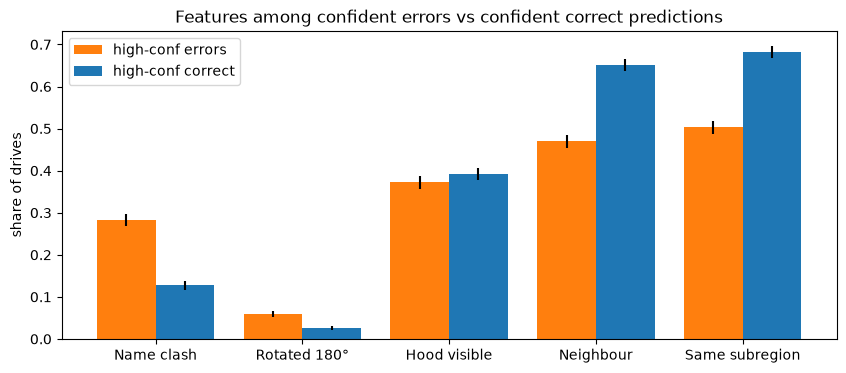

,error,error_ci,correct,correct_ci
feature,,,,
Name clash,0.283,0.014,0.128,0.010
Rotated 180°,0.059,0.007,0.025,0.005
Hood visible,0.373,0.015,0.392,0.015
Neighbour,0.470,0.016,0.652,0.015
Same subregion,0.503,0.016,0.683,0.014


In [7]:
features = {"name_clash": "Name clash", "rotated": "Rotated 180°", "hood_visible": "Hood visible",
            "is_neighbor": "Neighbour", "same_subregion": "Same subregion"}

rows = []
for col, label in features.items():
    s = seq_share(work, col)
    rows.append({"feature": label,
                 "error": s.loc["high-conf ERROR", "share"], "error_ci": s.loc["high-conf ERROR", "ci"],
                 "correct": s.loc["high-conf correct", "share"], "correct_ci": s.loc["high-conf correct", "ci"]})
comp = pd.DataFrame(rows).set_index("feature")

x = np.arange(len(comp))
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, comp["error"], 0.4, yerr=comp["error_ci"], color="tab:orange", label="high-conf errors")
plt.bar(x + 0.2, comp["correct"], 0.4, yerr=comp["correct_ci"], color="tab:blue", label="high-conf correct")
plt.xticks(x, comp.index)
plt.ylabel("share of drives")
plt.title("Features among confident errors vs confident correct predictions")
plt.legend()
plt.show()
display(comp.round(3))

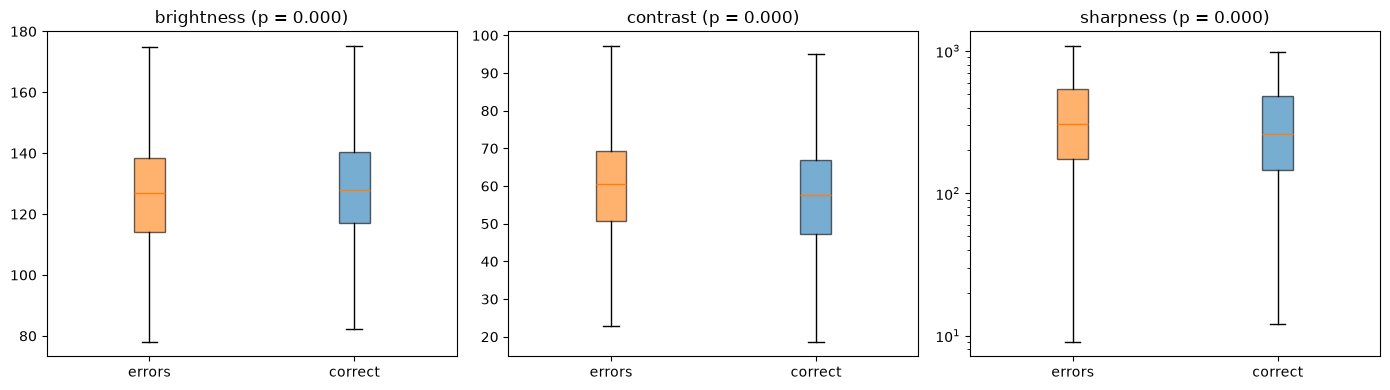

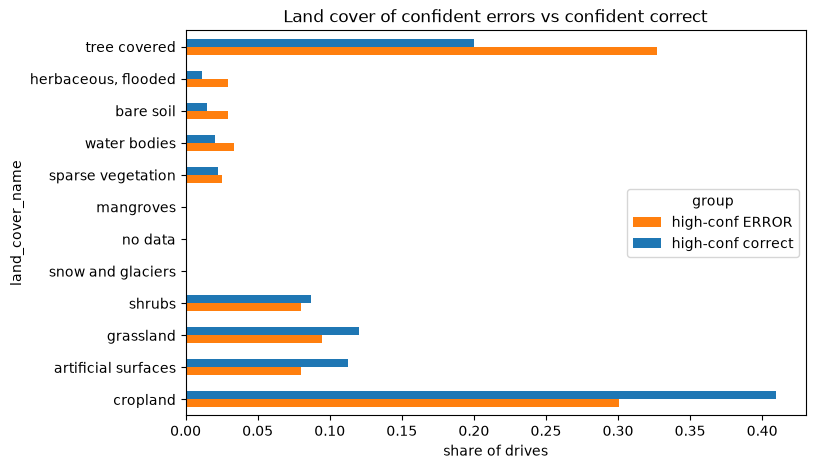

In [8]:
from scipy.stats import mannwhitneyu
# image quality: one value per drive (median), otherwise long drives dominate
per_drive = (work.groupby(["group", "sequence"])[["brightness", "contrast", "sharpness"]]
             .median().reset_index())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["brightness", "contrast", "sharpness"]):
    err = per_drive.loc[per_drive["group"] == "high-conf ERROR", col]
    cor = per_drive.loc[per_drive["group"] == "high-conf correct", col]
    box = ax.boxplot([err, cor], tick_labels=["errors", "correct"], showfliers=False, patch_artist=True)
    for patch, c in zip(box["boxes"], ["tab:orange", "tab:blue"]):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)
    ax.set_title(f"{col} (p = {mannwhitneyu(err, cor).pvalue:.3f})")
    if col == "sharpness":
        ax.set_yscale("log")
plt.tight_layout()
plt.show()

# scene type: land cover, each drive once
drives = work.drop_duplicates(["group", "sequence"])
scene = pd.crosstab(drives["land_cover_name"], drives["group"], normalize="columns")
scene["diff"] = scene["high-conf ERROR"] - scene["high-conf correct"]
scene = scene.sort_values("diff")
scene[["high-conf ERROR", "high-conf correct"]].plot(kind="barh", figsize=(8, 5),
                                                    color=["tab:orange", "tab:blue"])
plt.xlabel("share of drives")
plt.title("Land cover of confident errors vs confident correct")
plt.show()

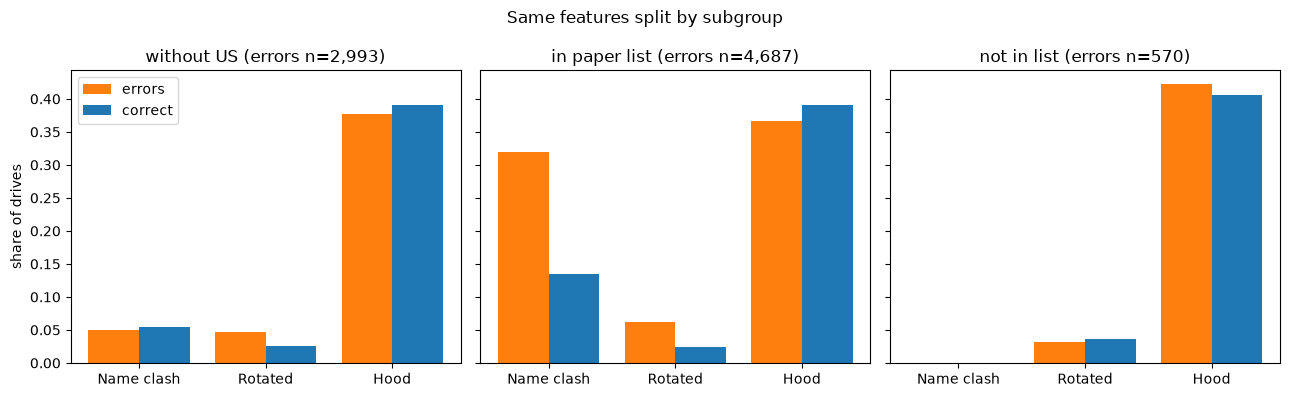

In [9]:
subsets = {"without US": work[work["country_id"] != "US"],
           "in paper list": work[work["in_list"]],
           "not in list": work[~work["in_list"]]}
cols = ["name_clash", "rotated", "hood_visible"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, data) in zip(axes, subsets.items()):
    err, cor = [], []
    for c in cols:
        s = seq_share(data, c)
        err.append(s.loc["high-conf ERROR", "share"])
        cor.append(s.loc["high-conf correct", "share"])
    x = np.arange(len(cols))
    ax.bar(x - 0.2, err, 0.4, color="tab:orange", label="errors")
    ax.bar(x + 0.2, cor, 0.4, color="tab:blue", label="correct")
    ax.set_xticks(x, ["Name clash", "Rotated", "Hood"])
    ax.set_title(f"{name} (errors n={data['is_error'].sum():,})")
axes[0].set_ylabel("share of drives")
axes[0].legend()
plt.suptitle("Same features split by subgroup")
plt.tight_layout()
plt.show()

,,images,drives
country_id,pred_1,,
US,GE,1127,918
GB,IE,106,92
US,MX,62,40
NG,NE,15,12
KR,KP,6,3


region
Georgia           401
North Carolina    347
South Carolina    271
Alabama           243
Mississippi       211
Arkansas          145
Virginia          139
Louisiana         139
Name: US -> GE images, dtype: int64

pred_1
GE    401
US     36
AR      3
UY      2
PY      2
Name: state of Georgia predicted as, dtype: int64

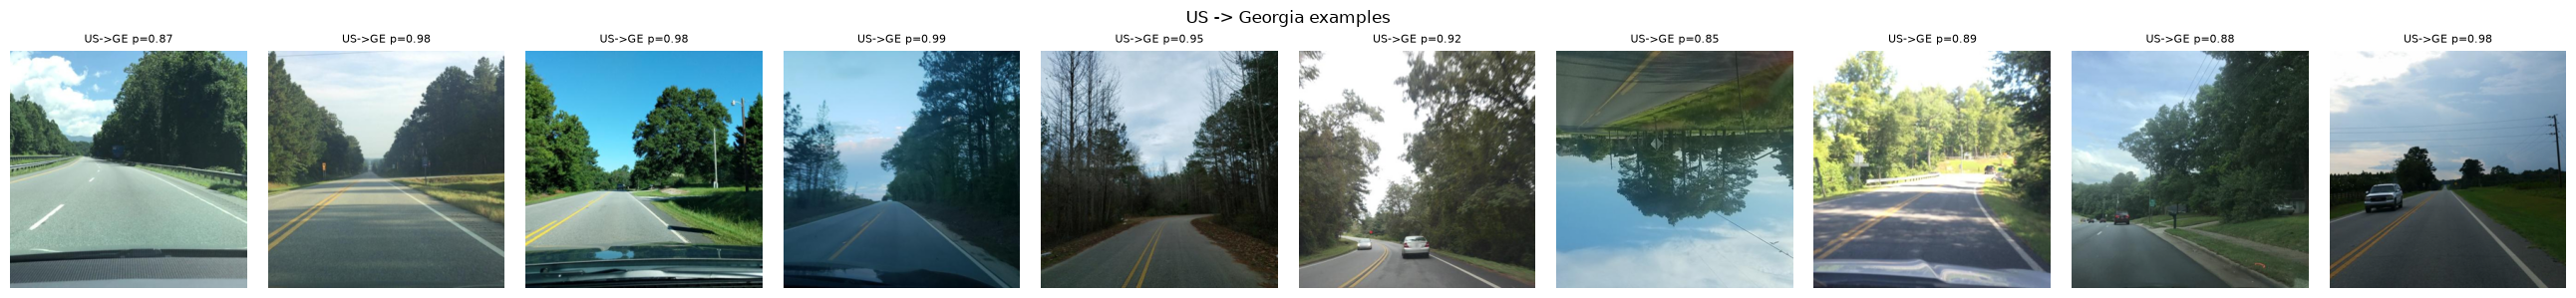

290 rotated confident errors, median confidence 0.87


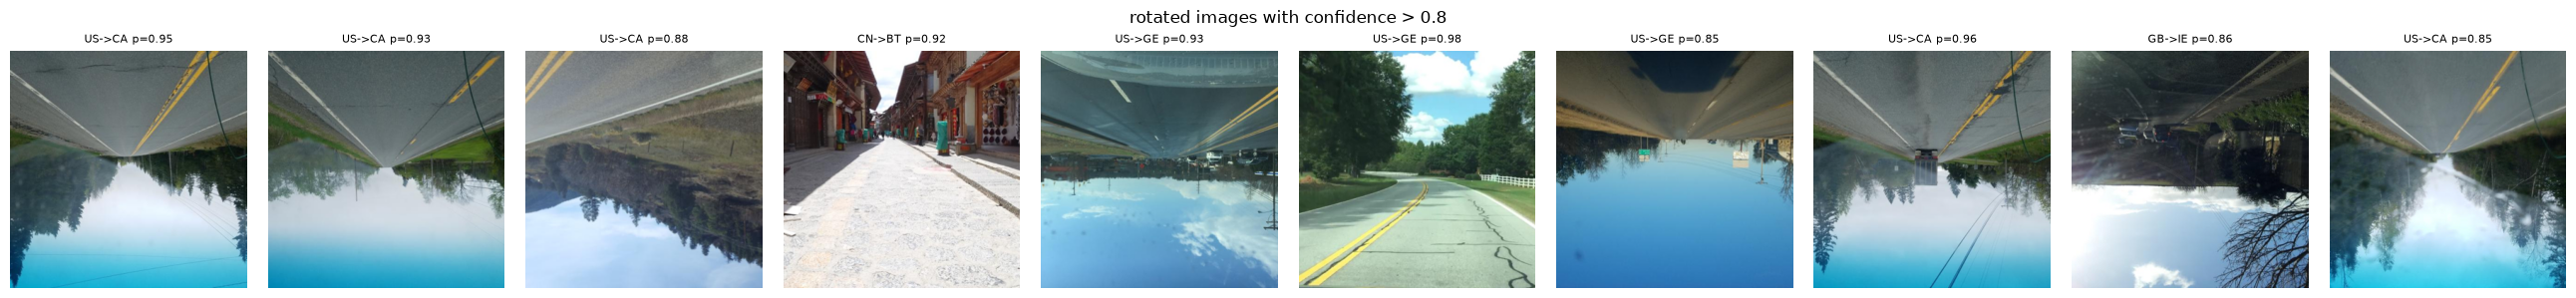

In [10]:
# which name clashes?
clash = work[work["is_error"] & work["name_clash"]]
display(clash.groupby(["country_id", "pred_1"])
        .agg(images=("id", "size"), drives=("sequence", "nunique"))
        .sort_values("images", ascending=False))

# are the US -> Georgia errors really from the state of Georgia?
us_ge = df[(df["country_id"] == "US") & (df["pred_1"] == "GE")]
display(dataset.meta.loc[us_ge["id"], "region"].value_counts().head(8).rename("US -> GE images"))

# and the other way round: what does the model say for the state of Georgia?
ga = df[(df["country_id"] == "US") & (dataset.meta.loc[df["id"], "region"].values == "Georgia")]
display(ga["pred_1"].value_counts().head(5).rename("state of Georgia predicted as"))

gallery(dataset, clash[clash["pred_1"] == "GE"].sample(10, random_state=0), cfg.crop_mode,
        "US -> Georgia examples")

rot_err = work[work["is_error"] & work["rotated"]]
print(f"{len(rot_err)} rotated confident errors, median confidence {rot_err['prob_1'].median():.2f}")
gallery(dataset, rot_err.sample(min(10, len(rot_err)), random_state=0), cfg.crop_mode,
        "rotated images with confidence > 0.8")

**F2 notes:** The biggest cause isn't visual at all. 28% of confident errors (counted per drive) are name clashes, compared to 13% in the matched reference. Almost all of them are US -> Georgia: 1,127 images from 918 drives. They don't only come from the state of Georgia but from the whole US Southeast (Georgia, North and South Carolina, Alabama, Mississippi, ...). The other way round it's even clearer: about 90% of the images from the state of Georgia get predicted as the country Georgia (401 vs 36 as US). So the model recognises the region fine but maps it to the wrong word in the prompt. The smaller cases follow the same idea: UK -> Ireland (106 images, probably Northern Ireland), US -> Mexico (maybe New Mexico), Nigeria -> Niger and South Korea -> North Korea. Without the US the effect disappears completely (5% vs 5%), so it's basically a Georgia problem.

Rotated images are the second cause (6% vs 2.5% of drives). They're clearly broken inputs, but the model still gives them a median confidence of 0.87. The effect holds without the US (4.7% vs 2.6%) and for listed countries, but not for unlisted ones (3% vs 4%). Our rotation flag isn't perfect though: a few upright images with very bright ground (light pavement, white gravel) get flagged too, so the real numbers are a bit lower.

Things that didn't explain the errors:
- Hood/dashboard view: 37% vs 39% of drives, no difference.
- Neighbouring countries: confident errors are actually less often a neighbour (47%) than the 2nd guess of correct predictions (65%). So confident errors aren't near misses, they tend to be far off, which fits the Georgia case. (Not a perfectly fair comparison, since we compare the wrong guess with a 2nd guess.)
- Image quality: brightness, contrast and sharpness are all "significant" (p < 0.001), but only because we have ~7,600 drives. The medians are almost the same (brightness 127 vs 128), and if anything errors are slightly sharper, so blur isn't the problem. Night can't really be tested: the darkest images are mostly shadowed or backlit daytime shots, with only one real night shot.
- Scene type: errors are more often on tree-covered roads (33% vs 20%) and less often in cropland (30% vs 41%). That fits the forest roads in the US -> Georgia examples, so it's probably the same effect and not a separate cause.

So the model can be confidently wrong about a place it actually recognises. That means confidence and accuracy alone can't tell us what it was trained on, so we need a comparison against plain CLIP.

## F3: Can we infer the training countries?

Accuracy alone is a weak signal, since some countries are just easy or already known to CLIP. So we compare StreetCLIP with plain CLIP on the pilot set (50 images per country) and look at the accuracy gain per country. We first tried the error reduction (share of CLIP's errors that StreetCLIP fixes), but it blows up when CLIP is already near 100% (Finland: CLIP 100%, StreetCLIP 76%, which gives -4.8), so we use the plain gain. A country counts as clearly improved if the gain is more than ~2 standard errors above 0. We do this without the paper's list first and only compare afterwards.

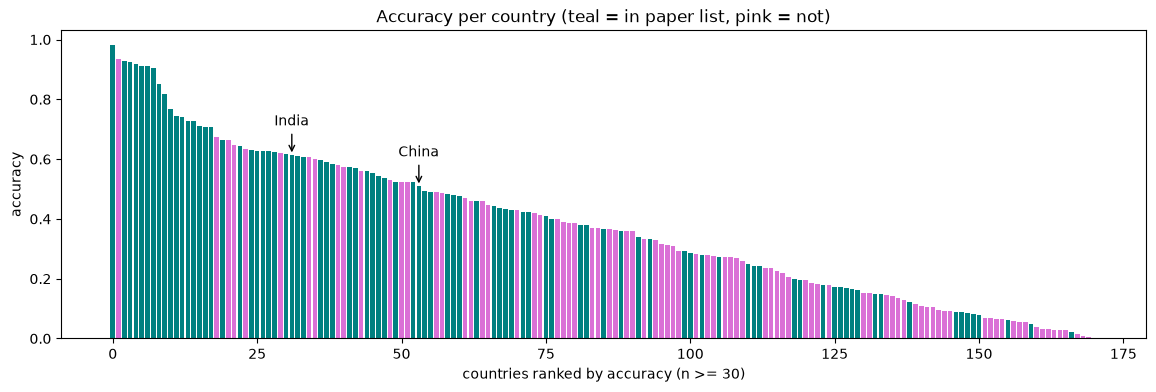

largest drops between neighbours in the ranking:
country_id
BT    0.051
BW    0.049
GL    0.047
Name: accuracy, dtype: float64


In [11]:
per_country = df.groupby("country_id").agg(n=("correct", "size"), accuracy=("correct", "mean"))
per_country = per_country[per_country["n"] >= 30].sort_values("accuracy", ascending=False)
per_country["in_list"] = per_country.index.map(attrs["in_paper_training_list"]).fillna(0).astype(int) == 1
per_country["name"] = per_country.index.map(attrs["prompt_name"])

plt.figure(figsize=(14, 4))
plt.bar(range(len(per_country)), per_country["accuracy"],
        color=np.where(per_country["in_list"], "teal", "orchid"))
for c in ["IN", "CN"]:
    if c in per_country.index:
        pos = per_country.index.get_loc(c)
        acc = per_country.loc[c, "accuracy"]
        plt.annotate(per_country.loc[c, "name"], (pos, acc), xytext=(pos, acc + 0.1),
                     ha="center", arrowprops=dict(arrowstyle="->"))
plt.xlabel("countries ranked by accuracy (n >= 30)")
plt.ylabel("accuracy")
plt.title("Accuracy per country (teal = in paper list, pink = not)")
plt.show()

print("largest drops between neighbours in the ranking:")
print(per_country["accuracy"].diff(-1).nlargest(3).round(3))

In [12]:
clip_dir = Path(f"results/pair_b/clip_pilot_{cfg.candidate_list}_{cfg.crop_mode}")
if not clip_dir.exists():   # takes ~4 min the first time
    clip = GeoCLIPModel(cfg.clip_model, cfg)
    cands = mapper.candidates(cfg.candidate_list)
    clip.set_candidates(cands, mapper.prompts(cands, cfg.prompt_template))
    PredictionRunner(cfg, dataset, mapper).run(clip, pilot_ids, run_name=clip_dir.name, out_dir=clip_dir)
    free_gpu_memory()
clip_preds, _, _, _ = PredictionRunner.load(clip_dir)

def pilot_acc(table):
    t = table[table["representable"]].copy()
    t["correct"] = t["correct"].astype(bool)
    return t.groupby("country_id")["correct"].agg(["mean", "size"])

sc = pilot_acc(preds[preds["id"].isin(set(pilot_ids))])
cl = pilot_acc(clip_preds)
gain = pd.DataFrame({"streetclip": sc["mean"], "clip": cl["mean"], "n": sc["size"]}).dropna()
gain["gain"] = gain["streetclip"] - gain["clip"]
# rough standard error; both models see the same images, so treating them as independent overestimates it
gain["se"] = np.sqrt((gain["streetclip"] * (1 - gain["streetclip"])
                      + gain["clip"] * (1 - gain["clip"])) / gain["n"])
gain["in_list"] = gain.index.map(attrs["in_paper_training_list"]).fillna(0).astype(int) == 1
print(f"{len(gain)} countries, median n = {gain['n'].median():.0f}, median se of the gain = {gain['se'].median():.2f}")



188 countries, median n = 50, median se of the gain = 0.09


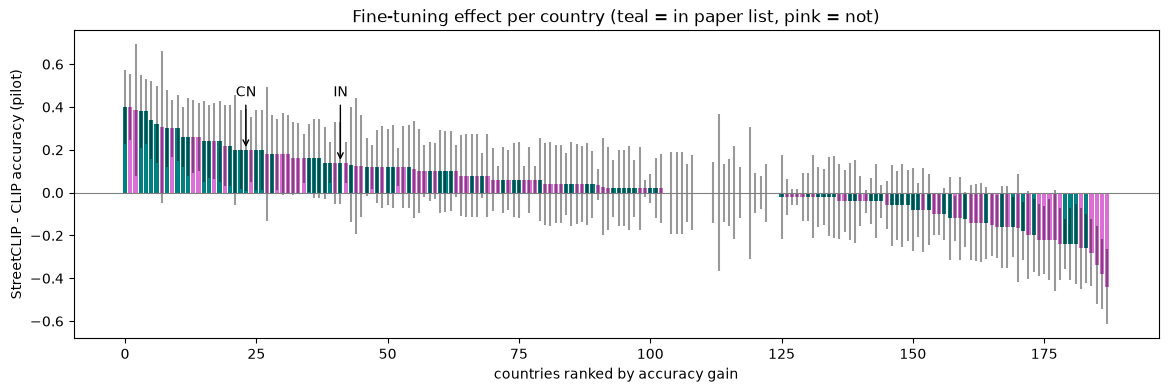

in_list,in paper list,not in list,All
effect,,,
clearly better,19,13,32
clearly worse,7,14,21
no clear change,63,72,135
All,89,99,188


countries with negative gain: 63 of 188


,streetclip,clip,gain,se,n,effect,in_list
country_id,,,,,,,
SV,0.46,0.06,0.40,0.08,50,clearly better,False
PE,0.56,0.16,0.40,0.09,50,clearly better,True
BJ,0.46,0.08,0.38,0.16,13,clearly better,False
LV,0.44,0.06,0.38,0.08,50,clearly better,True
CL,0.54,0.16,0.38,0.09,50,clearly better,True
TH,0.62,0.28,0.34,0.09,50,clearly better,True
TW,0.54,0.22,0.32,0.09,50,clearly better,True
SE,0.78,0.48,0.30,0.09,50,clearly better,True
UZ,0.32,0.02,0.30,0.07,50,clearly better,False


In [13]:
# error reduction explodes when CLIP is already near 100% (FI: -4.8), so we classify on the plain gain
# a country counts as clearly better / worse if the gain is more than ~2 standard errors away from 0
gain["effect"] = np.select(
    [gain["gain"] > 1.96 * gain["se"], gain["gain"] < -1.96 * gain["se"]],
    ["clearly better", "clearly worse"], default="no clear change")
gain["inferred"] = gain["effect"] == "clearly better"

g = gain.sort_values("gain", ascending=False)
plt.figure(figsize=(14, 4))
plt.bar(range(len(g)), g["gain"], yerr=1.96 * g["se"],
        color=np.where(g["in_list"], "teal", "orchid"), error_kw={"alpha": 0.4})
plt.axhline(0, color="gray", linewidth=0.8)
for c in ["IN", "CN"]:
    if c in g.index:
        pos = g.index.get_loc(c)
        plt.annotate(c, (pos, g.loc[c, "gain"]), xytext=(pos, g["gain"].max() + 0.05),
                     ha="center", arrowprops=dict(arrowstyle="->"))
plt.xlabel("countries ranked by accuracy gain")
plt.ylabel("StreetCLIP - CLIP accuracy (pilot)")
plt.title("Fine-tuning effect per country (teal = in paper list, pink = not)")
plt.show()

display(pd.crosstab(gain["effect"], gain["in_list"].map({True: "in paper list", False: "not in list"}),
                    margins=True))
print("countries with negative gain:", (gain["gain"] < 0).sum(), "of", len(gain))

cols = ["streetclip", "clip", "gain", "se", "n", "effect", "in_list"]
display(gain[gain.index.isin(["IN", "CN"]) | (gain["effect"] != "no clear change")][cols]
        .sort_values("gain", ascending=False).round(2))

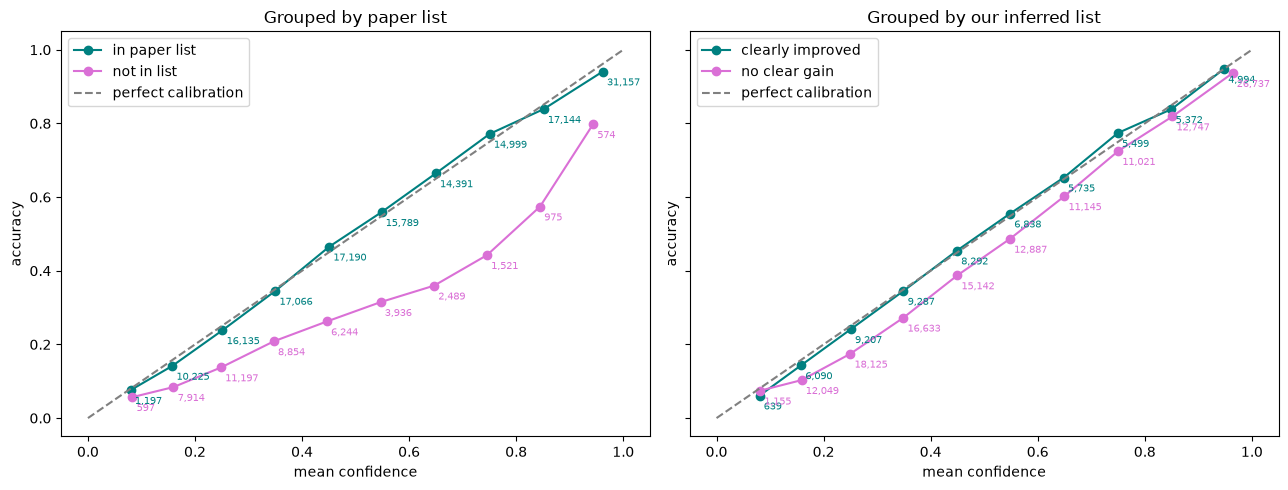

,paper list,inferred
trained / listed,0.015,0.009
not trained / not listed,0.151,0.051


In [14]:
# back to F1: is calibration cleaner if we group by our inferred list?
df["inferred"] = df["country_id"].map(gain["inferred"])
known = df[df["inferred"].notna() & ~df["id"].isin(set(pilot_ids))].copy()   # pilot images left out
known["inferred"] = known["inferred"].astype(bool)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
reliability(axes[0], known, "in_list", LIST_LABELS)
axes[0].set_title("Grouped by paper list")
reliability(axes[1], known, "inferred", {True: ("clearly improved", "teal"),
                                         False: ("no clear gain", "orchid")})
axes[1].set_title("Grouped by our inferred list")
plt.tight_layout()
plt.show()

def ece(data):
    b = data.groupby(pd.cut(data["confidence"], np.linspace(0, 1, 11)), observed=True)
    return ((b["correct"].mean() - b["confidence"].mean()).abs() * b.size() / len(data)).sum()

pd.DataFrame({
    "paper list": {k: ece(known[known["in_list"] == k]) for k in [True, False]},
    "inferred": {k: ece(known[known["inferred"] == k]) for k in [True, False]},
}).rename(index={True: "trained / listed", False: "not trained / not listed"}).round(3)




**F3 notes:** Ranked by accuracy there's no step, more of a smooth slope: the biggest drop between two neighbours in the ranking is only 5 points. Listed and unlisted countries are mixed along the whole ranking, only the top ~20 are almost all listed.

The fine-tuning gain doesn't show a clear cut either. With 50 pilot images per country the standard error of the gain is about 0.09, so most countries (135 of 188) show no clear change. 32 countries clearly improve and 21 clearly get worse. There is a tendency in the right direction: 21% of listed countries clearly improve vs 13% of unlisted ones, and 8% of listed vs 14% of unlisted clearly get worse. But that's far from a clean split: 13 unlisted countries clearly improve (e.g. El Salvador, Uzbekistan, Timor-Leste), and 7 listed ones clearly get worse (e.g. Finland 100% to 76%, Botswana 92% to 76%). In total 63 of 188 countries get worse with fine-tuning. Some unlisted gains might come from trained neighbours (e.g. Timor-Leste next to Indonesia), but we can't check that here. A few values are shaky: Benin and Kuwait have fewer pilot images (13 and 33), and for countries at exactly 0% or 100% our standard error is too small.

India goes from 50% to 64% (+14 points), about 1.4 standard errors, so we can't say it clearly improved. China goes from 34% to 54% (+20 points), right at 2 standard errors, so it looks like fine-tuning helped there. Both are in the list we used. The paper says it trained on 101 countries but only lists 92, and the model card says India and China were excluded, while the list includes both. Our in_paper_training_list column follows the list as printed in the paper, so India and China count as listed.

The clearest hint about training coverage is calibration, not accuracy. Grouped by the paper's list the calibration error is 0.015 vs 0.151 (listed vs unlisted), grouped by our inferred list it's only 0.009 vs 0.051. So the paper's list separates well-calibrated from badly calibrated countries much better than our own list, which suggests the paper's list is roughly right and our gain-based inference is just too noisy with 50 images per country. As in F1, harder countries tend to be worse calibrated anyway, so this isn't a clean proof either.

## Answer to Q2

StreetCLIP is confidently wrong mostly when a country name is ambiguous, above all the US state of Georgia vs the country Georgia (28% vs 13% of drives, almost all from the US Southeast), and on rotated images (6% vs 2.5%). Dashcam/hood view, image quality, neighbouring countries and scene type don't explain the errors. Its confidence is reliable for the countries in the paper's list and too high for the rest, although it rarely gets very confident there. We can't cleanly infer the training countries from the outputs: accuracy drops smoothly across countries, and with 50 pilot images per country most fine-tuning gains are within noise. China clearly improves through fine-tuning, India improves but not clearly. There's no hard cut between known and unknown countries, only a weak tendency: listed countries improve a bit more often and get worse less often. The strongest hint that the paper's list is roughly right is calibration: it separates well-calibrated from overconfident countries much better (0.015 vs 0.151) than our own inferred list does.

**F1: Calibrated where trained, overconfident elsewhere**
- Pattern: reliability curve close to the diagonal for listed countries, clearly below it for unlisted ones.
- Drill-down: unlisted countries rarely reach high confidence; confident errors are more common in listed countries (2.9% vs 1.2%), mostly because of the US (1.8% vs 1.2% without it).
- Explanation: fine-tuning gave reliable confidence for countries the model saw; for the rest it's unsure, but still not unsure enough. Part of it may also be that unlisted countries are harder.
- Evidence: reliability diagram with bin counts, group shares, check without the US, calibration error with paper vs inferred list.
- Phase II: does temperature scaling per group remove the gap?

**F2: Confident errors come from name ambiguity and rotated images**
- Pattern: name clashes 28% vs 13%, rotated 6% vs 2.5% (country-matched reference, each drive counted once).
- Drill-down: US -> Georgia (1,127 images, 918 drives, whole US Southeast; ~90% of images from the state of Georgia are predicted as the country), plus UK -> Ireland, US -> Mexico, Nigeria -> Niger, South Korea -> North Korea. Rotated images still above 0.8.
- Explanation: StreetCLIP matches the word in the prompt, and "Georgia" also means the US state. Rotated images are out of distribution but don't lower the confidence.
- Evidence: feature shares with CIs, subgroup split (name clash disappears without the US), region counts, galleries. Hood view, neighbours and scene type show no real difference; image quality is significant but tiny.
- Phase II: where does the model look on US -> Georgia images (Grad-CAM)? Does a prompt like "Georgia (country)" remove the errors?

**F3: Training coverage**
- Pattern: smooth slope in accuracy (largest gap 5 points); fine-tuning gain is within noise for 135 of 188 countries, no clear cut.
- Drill-down: 32 clearly better (19 listed / 13 not), 21 clearly worse (7 / 14). India +14 points (not clear), China +20 points (just clear). Finland and Botswana get worse although listed.
- Explanation: with 50 images per country the gain is too noisy to classify single countries. The calibration gap fits the paper's list much better than our inferred list (0.015 vs 0.151 compared to 0.009 vs 0.051).
- Evidence: gain ranking with 95% intervals, effect vs paper list table, calibration error with paper vs inferred list.
- Phase II: more pilot images per country to narrow the intervals for the borderline countries.